# EquityAgent: Evidence-Grounded Agentic Equity Research

**AAI 520: Natural Language Processing and Generative AI | Final project**
University of San Diego · Master of Science in Applied Artificial Intelligence · October 2026

**Research team:** Nicole Rowley (agent orchestration), Ashley Figueroa (NLP), and Pawan Bishwokarma (evaluation).
**Code and reproducibility:** [EquityAgent GitHub repository](https://github.com/nicole-rowley-msaai/MS_AAI_520_NLP_GenAI_Final)

### Abstract

EquityAgent combines financial information retrieval, sentiment NLP and
an iterative language-model research workflow. A LangGraph agent plans
research for a stock ticker, routes tasks to earnings, market and news
specialists that gather market, macroeconomic, filing and news evidence,
verifies every figure in their findings against the raw tool data,
synthesizes an equity brief, and revises it under a quality gate that
checks rubric scores and recognized figures. A reflection step stores
lessons that the next run's planner reads. The news component benchmarks
LLM sentiment classification against keyword and supervised baselines.
The agent component compares the brief with a no-tools baseline and with
a single-pass brief written from the same evidence, and tests the effect
of stored lessons. Experiments cover NVDA, JPM and XOM.

### How to read this notebook

The notebook is one executable document. Every table, figure and number
in the text below was produced by the code cells in this run; nothing is
carried over from earlier runs. It has three parts, which follow the data
through the system:

| Part | Question | Where the evidence is |
|---|---|---|
| **A. Data and sentiment modeling** | Do the financial data tools work, and how well does an LLM classify financial sentiment against a keyword rule and a supervised baseline? | A1 tool checks; A2 dataset cleaning; A3–A4 classifier comparison; A5 metrics and variation |
| **B. One research run, step by step** | What does the agent do with a ticker, and can each step be inspected? | B2 plan; B3 tool calls; B4 routing; B5 prompt chain; B6 findings; B6b verification; B7 evaluate–revise; B8 brief; B9 reflection; B10 memory |
| **C. Evaluation** | Is the agent better than simpler alternatives, and what do the quality controls change? | C1 baselines and memory; C2 acceptance policies; C3 limitations |

**The agent's workflow.** A ticker enters a LangGraph state graph and
passes through eight stages: *plan → route → specialists → verify →
synthesize → evaluate ⇄ optimize → reflect*. The planner reads stored
lessons and writes a research plan; the router sends each step to an
earnings, market or news specialist; the specialists call tools and
write findings, interleaving tool use with reasoning in the manner of
ReAct (Yao et al., 2023), with 10-K text retrieved by semantic search
over filing sections (Lewis et al., 2020); a data verification
specialist checks every figure in the findings against the raw tool
output; the synthesizer writes a brief; an evaluator scores it and an
optimizer revises it until a quality gate is met, following the
generate–evaluate–refine loop of Self-Refine (Madaan et al., 2023); and
a reflection step records lessons that the next run's planner reads,
as in Reflexion (Shinn et al., 2023).

**Models.** The planner, router and news chain use `gpt-6-luna`; the
specialists, synthesizer and optimizer use `claude-sonnet-5`; the
evaluator uses `gpt-6-sol`, a different model family from the writer so
that drafts are not graded by the model that wrote them. The
verification specialist uses no model: it is rule-based, so its checks
are reproducible.

<!-- AAI520_PUBLICATION_POLISH_V1 -->
## Research questions and experimental design

1. **Financial NLP:** How does an LLM sentiment classifier compare with keyword
   classification and TF–IDF logistic regression on a held-out set of labeled
   financial news sentences?
2. **Research agent:** How do an evidence-informed research process and its
   revision loop compare with generation from a single prompt, with and
   without access to the same evidence?
3. **Evaluation controls:** Do explicit evidence and accuracy thresholds, plus
   constrained numerical cross-checks, change which generated drafts are
   considered acceptable?

| Component | Data or comparison | Primary evidence |
|---|---|---|
| Sentiment NLP | Financial PhraseBank sentences; held-out test set | Accuracy, macro-F1, confusion matrix, agreement-band analysis |
| Agent research | NVDA, JPM, XOM; market, macro, filing, and news findings | Tool trace, verified findings, research brief, five-criterion LLM rubric |
| Quality controls | Original versus reviewed policies applied to the same scored revisions | Threshold decisions, recognized numeric claims, selected revision |
| Memory | Repeated runs with and without stored lessons | Planning steps, notes retrieved, rubric scores |

The original and reviewed policies reuse the **same evaluator model**; the
comparison isolates their acceptance rules, not two separately trained judges.
Agent calls and external data sources are nondeterministic. Results reflect
the data and model responses available at execution time.

### Assessment requirements and implementation map

The notebook explicitly demonstrates the **four agent functions** and the
**three workflow patterns** required by the assignment, plus one addition.

| Grading area | Required capability | Execution evidence |
|---|---|---|
| Agent Functions | Plans research steps for a stock symbol | **B2**: research plan and task sequence |
| Agent Functions | Uses tools dynamically through APIs, datasets, and retrieval | **B3**: tool calls, inputs, and results |
| Agent Functions | Self-reflects on the quality of its output | **B9**: reflection, unsupported claims, lessons |
| Agent Functions | Learns across runs using persistent notes | **B10**: lessons saved and retrieved by a subsequent plan, which cites them |
| Workflow Patterns | **Prompt Chaining:** Ingest → Preprocess → Classify → Extract → Summarize | **B5**: intermediate outputs for each news processing stage |
| Workflow Patterns | **Routing:** Direct research tasks to appropriate specialists | **B4**: earnings, market, and news routing decisions |
| Workflow Patterns | **Evaluator–Optimizer:** Generate → Evaluate → Refine | **B7**: scored draft iterations, feedback, numerical audit, and final selection |
| Addition | **Data verification:** findings checked against raw tool data before synthesis | **B6b**: figures confirmed, corrected or flagged per specialist |

The writer and optimizer use **Claude Sonnet 5** (`claude-sonnet-5`), while
**GPT-6 Sol** (`gpt-6-sol`) grades their drafts against the rubric. These
roles separate report generation from LLM-based evaluation. Two further
checks use no model: the verification specialist (`src/agents/verifier.py`)
compares every figure in the findings with the raw tool output, and the
numeric audit compares recognized figures in the brief with the findings.

## Setup

In [1]:
# --- Colab setup -----------------------------------------------------
import importlib
import os
import subprocess
import sys

from google.colab import drive, userdata

os.chdir("/content")
drive.mount("/content/drive")

# Use an isolated copy because the memory experiment resets local notes.
BRANCH = "main"
REPO = "/content/drive/MyDrive/equity-agent-v10"
REPO_URL = (
    "https://github.com/nicole-rowley-msaai/"
    "MS_AAI_520_NLP_GenAI_Final.git"
)

if os.path.isdir(os.path.join(REPO, ".git")):
    # Match GitHub exactly. A plain pull can stop on files an earlier run
    # changed in this copy (memory notes, Table 1). The copy exists only
    # for runs, so those changes are discarded; untracked downloads such
    # as the Kaggle CSV are kept.
    !git -C {REPO} fetch -q origin
    !git -C {REPO} checkout -q -B {BRANCH} origin/{BRANCH}
    !git -C {REPO} reset -q --hard origin/{BRANCH}
else:
    !git clone -q --branch {BRANCH} {REPO_URL} {REPO}
%cd {REPO}
COMMIT = subprocess.run(
    ["git", "-C", REPO, "rev-parse", "--short", "HEAD"],
    capture_output=True, text=True,
).stdout.strip()
!git log -1 --format='%h %an  %s'

# Forget EquityAgent modules that an earlier "Run all" in this session
# imported, so the next cell loads the code just checked out.
for name in [m for m in sys.modules if m == "src" or m.startswith("src.")]:
    del sys.modules[name]
importlib.invalidate_caches()
if REPO not in sys.path:
    sys.path.insert(0, REPO)

SKIP = r"google-adk\|dependency resolver"
!pip install -q -r requirements.txt 2>&1 | grep -v "{SKIP}"

# Kaggle: newer accounts issue one KAGGLE_API_TOKEN; older ones use
# KAGGLE_USERNAME + KAGGLE_KEY. Either set is enough.
SECRET_KEYS = [
    "OPENAI_API_KEY",
    "ANTHROPIC_API_KEY",
    "FRED_API_KEY",
    "NEWSAPI_KEY",
    "EDGAR_USER_AGENT",
    "KAGGLE_API_TOKEN",
    "KAGGLE_USERNAME",
    "KAGGLE_KEY",
]
loaded, missing = [], []
for key in SECRET_KEYS:
    try:
        os.environ[key] = userdata.get(key)
        loaded.append(key)
    except Exception:
        missing.append(key)
kaggle_ok = "KAGGLE_API_TOKEN" in loaded or {
    "KAGGLE_USERNAME", "KAGGLE_KEY"} <= set(loaded)
missing = [k for k in missing if not k.startswith("KAGGLE_")]
if not kaggle_ok:
    missing.append("KAGGLE_API_TOKEN (or KAGGLE_USERNAME + KAGGLE_KEY)")
print("Loaded:", loaded)
if missing:
    print("Missing secrets:", missing)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/equity-agent-v10
09782eb nicole-rowley-msaai  Notebook code cells to PEP 8 (79 columns)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 639.0/639.0 kB 29.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 168.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 155.6/155.6 kB 21.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.2/86.2 kB 11.7 MB/s eta 0:00:00
google-colab 1.0.0 requires ipython==7.34.0, but you have ipython 9.17.1 which is incompatible.
Loaded: ['OPENAI_API_KEY', 'ANTHROPIC_API_KEY', 'FRED_API_KEY', 'NEWSAPI_KEY', 'EDGAR_USER_AGENT', 'KAGGLE_USERNAME', 'KAGGLE_KEY']


In [2]:
import logging
import warnings

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

logging.getLogger("huggingface_hub").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", module="huggingface_hub")

from src import display as show  # noqa: E402
from src.config import TICKERS  # noqa: E402
from src.evaluation import (  # noqa: E402
    baseline_brief,
    quick_smoke,
    score_against_findings,
    tool_success_rate,
    unsupported_figures,
)
from src.graph import run_agent  # noqa: E402
from src.memory import store  # noqa: E402
from src.tools import safe_call  # noqa: E402
from src.tools.retrieval import index_filings  # noqa: E402

pd.set_option("display.max_colwidth", 120)

# Stop before any agent run if the code did not come from this checkout.
import src.graph as _graph  # noqa: E402

assert os.path.realpath(_graph.__file__).startswith(
    os.path.realpath(REPO)
), (
    f"Agent code was imported from {_graph.__file__}, not {REPO}. "
    "Use Runtime > Restart session, then Run all."
)
print(f"Agent code loaded from {REPO} at commit {COMMIT}")


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Agent code loaded from /content/drive/MyDrive/equity-agent-v10 at commit 09782eb


In [3]:
# Record the effective configuration used for this execution.
from datetime import datetime, timezone
from src.config import MODELS

print(
    "Execution date (UTC):",
    datetime.now(timezone.utc).isoformat(timespec="seconds"),
)
print("Configured models:", {key: MODELS[key] for key in
                             ("chain", "writer", "evaluator", "embeddings")})


Execution date (UTC): 2026-10-19T23:04:47+00:00
Configured models: {'chain': 'gpt-6-luna', 'writer': 'claude-sonnet-5', 'evaluator': 'gpt-6-sol', 'embeddings': 'all-MiniLM-L6-v2'}


# Part A. Financial data and sentiment modeling

## Agent Functions and Capabilities

This section verifies the agent's financial data tools, explores the
labeled financial news dataset, and benchmarks sentiment classification
using keyword rules, TF–IDF logistic regression, and zero-shot or few-shot
LLM prompting. The classifier study uses a fixed, stratified held-out
sample of 300 sentences, three LLM trials per prompting condition, and a
separate agreement-band analysis. Tool calls expose success and failure
states for inspection rather than assuming every external source is
available.

## A1. Data check: does every tool return data?

Each call goes through `safe_call`, so a failed API shows as `ok=False`
instead of stopping the notebook.

In [4]:
from src.tools.filings import extract_sections, get_latest_10k
from src.tools.macro import get_macro_snapshot
from src.tools.market import compute_technicals, get_price_history
from src.tools.news import get_news


def status(result):
    """Every ToolResult field except the data itself."""
    return {k: v for k, v in vars(result).items() if k != "data"}


checks = []
spy = safe_call("prices", get_price_history, "SPY")
for ticker in TICKERS:
    prices = safe_call("prices", get_price_history, ticker)
    checks.append({"ticker": ticker, **status(prices)})
    if prices.ok and spy.ok:
        print(ticker, compute_technicals(prices.data, spy.data))

macro = safe_call("fred", get_macro_snapshot)
checks.append({"ticker": "-", **status(macro)})
pd.DataFrame(checks)

NVDA {'last_close': 217.09, 'return_1m': -0.0233, 'return_1y': 0.194, 'vol_annualized': 0.3728, 'sma_50': 222.94, 'sma_200': 203.12, 'beta_vs_spy': 2.129}
JPM {'last_close': 333.53, 'return_1m': -0.0462, 'return_1y': 0.1172, 'vol_annualized': 0.2212, 'sma_50': 347.64, 'sma_200': 322.42, 'beta_vs_spy': 0.87}
XOM {'last_close': 178.28, 'return_1m': 0.0901, 'return_1y': 0.6114, 'vol_annualized': 0.2601, 'sma_50': 164.19, 'sma_200': 152.01, 'beta_vs_spy': 0.382}


,ticker,tool,ok,error,meta
0,NVDA,prices,True,None,{'rows': 1254}
1,JPM,prices,True,None,{'rows': 1254}
2,XOM,prices,True,None,{'rows': 1254}
3,-,fred,True,None,{'rows': 5}


In [5]:
macro.data if macro.ok else macro.error

,series,label,date,latest,one_year_ago
0,CPIAUCSL,"CPI, all urban consumers",2026-09-01,336.298,324.245
1,FEDFUNDS,Effective federal funds rate,2026-09-01,3.750,4.220
2,DGS10,10-year Treasury yield,2026-10-16,5.090,3.990
3,UNRATE,Unemployment rate,2026-09-01,4.200,4.400
4,GDPC1,Real GDP,2026-04-01,24408.011,23884.563


In [6]:
news = safe_call("news", get_news, "NVDA", "Nvidia")
print(news.ok, news.meta, news.error)
pd.DataFrame(news.data[:5]) if news.ok else None

True {'rows': 99} None


,title,description,source,published,url
0,Nvidia says its new AI safety platform can contain rogue agents within ‘milliseconds’,"Nvidia is launching a new safety platform designed to contain and monitor AI agents, a move that comes in response t...",The Verge,2026-09-28T13:36:06Z,https://www.theverge.com/tech/1001287/nvidia-ai-safety-platform-rogue-agents
1,Nvidia launches agent safety platform backed by over 100 companies,"On Monday, Nvidia introduced the Open Agent Safety Platform. This includes open software and a hardware reference de...",The Next Web,2026-09-28T09:57:24Z,https://thenextweb.com/news/nvidia-open-agent-safety-platform
2,Nvidia commits $250M of compute to UK AI safety research,"Nvidia has committed $250M over five years to UK agentic safety and security research, in the form of compute access...",The Next Web,2026-10-14T08:24:26Z,https://thenextweb.com/news/nvidia-250m-uk-ai-safety
3,"Nvidia-backed Reflection unveils Beam, its first open-weight model","Reflection AI, the Nvidia-backed startup founded by former Google DeepMind researchers, has unveiled Beam, its first...",The Next Web,2026-10-05T22:01:57Z,https://thenextweb.com/news/reflection-ai-beam-open-weight-model
4,Nvidia adds a record $150bn to its share buyback,"Nvidia’s board has approved an extra $150bn for share buybacks, the company said on Monday. That lifts the total rem...",The Next Web,2026-09-28T18:23:31Z,https://thenextweb.com/news/nvidia-150bn-share-buyback-235bn-record


**10-K sections.** Three filer quirks surfaced during iteration, and
`src/tools/filings.py` handles each:

- **JPMorgan** embeds its whole annual report in the 10-K file, so "Item 7"
  is only a cross-reference. The extractor falls back to the plain heading
  "Management's discussion and analysis" when the Item 7 span is too short.
- **Exxon** reorganized into ExxonMobil Holdings Corp in mid-2026. The
  ticker now maps to a new SEC registrant with no 10-K, so the loader
  retries the prior entity's CIK from `config.PREDECESSOR_CIKS`.
- **Heavy filers** can push a 10-K off the first page of the SEC
  submissions feed, so the loader follows the paginated files.

The `cik` column below shows which registrant each 10-K came from.

In [7]:
secs = None
for ticker in TICKERS:
    filing = safe_call("edgar", get_latest_10k, ticker)
    if not filing.ok:
        print(ticker, filing.error)
        continue
    secs = extract_sections(filing.data)
    words = {k: len(v.split()) for k, v in secs.items()}
    print(ticker, "cik", filing.data["cik"], filing.data["filed"], words)

if secs:
    print()
    print(secs["mdna"][:500])

NVDA cik 0001045810 2026-02-25 {'risk_factors': 18339, 'mdna': 5252}
JPM cik 0000019617 2026-02-13 {'risk_factors': 15906, 'mdna': 59379}
XOM cik 0000034088 2026-02-18 {'risk_factors': 24758, 'mdna': 17544}

MANAGEMENT’S DISCUSSION AND ANALYSIS OF FINANCIAL CONDITION AND RESULTS OF OPERATIONS FORWARD-LOOKING STATEMENTS Statements related to future events; projections; descriptions of strategic, operating, and financial plans and objectives; statements of future ambitions and plans; future earnings power; potential addressable markets; and other statements of future events or conditions are forward-looking statements. Similarly, discussion of roadmaps or future plans related to carbon capture, transp


## A2. Kaggle news EDA

The labeled dataset is
[Kaggle: Sentiment Analysis for Financial News](https://www.kaggle.com/datasets/ankurzing/sentiment-analysis-for-financial-news)
(the Financial PhraseBank). The cell below downloads it once with the Kaggle
API; add `KAGGLE_API_TOKEN` (newer Kaggle accounts) or `KAGGLE_USERNAME`
and `KAGGLE_KEY` (older ones) to Colab Secrets, or drop `all-data.csv`
into `data/kaggle/` by hand.

The same sentences ship with the original release in
`data/kaggle/FinancialPhraseBank/` (Malo et al., 2014). Each sentence has
5 to 8 annotations, and the release groups sentences by how strongly the
annotators agreed (100%, over 75%, over 66%, over 50%). The classifier
diagnostics below use those groups to read the classifier's errors.

**Cleaning.** Rows are compared on a normalized key (case-folded,
punctuation removed), which finds near-duplicates that an exact match
misses (Jurafsky & Martin, 2026, Sections 2.4 and 2.6). A sentence that
appears with two different labels has no single gold label, so it is
dropped. The normalized key is used only for matching; the classifier
sees the original text, because case carries sentiment signal (Section
2.6).


In [8]:
# Download the Kaggle dataset once; it stays in Drive afterward.
from src.config import KAGGLE_CSV

DATASET = "ankurzing/sentiment-analysis-for-financial-news"

if not KAGGLE_CSV.exists():
    # Newer Kaggle accounts issue one API token; older ones a username and
    # key. Load whichever is in Colab Secrets.
    for name in ("KAGGLE_API_TOKEN", "KAGGLE_USERNAME", "KAGGLE_KEY"):
        try:
            os.environ.setdefault(name, userdata.get(name))
        except Exception:
            pass
    !pip install -q -U kaggle
    !kaggle datasets download -d {DATASET} -p data/kaggle --unzip
print("Kaggle CSV present:", KAGGLE_CSV.exists())


Kaggle CSV present: True


In [9]:
from src.chains.kaggle import (
    LABELS, clean_kaggle, cleaning_report, load_kaggle, train_test,
)

raw = load_kaggle()
print("Rows:", len(raw), "| Columns:", list(raw.columns))
print("Missing values:", raw.isna().sum().to_dict())
print("Cleaning:", cleaning_report(raw))
df = clean_kaggle(raw)
print("Rows after cleaning:", len(df))


Rows: 4846 | Columns: ['sentiment', 'headline']
Missing values: {'sentiment': 0, 'headline': 0}
Cleaning: {'rows': 4846, 'exact_duplicates': 8, 'normalized_duplicates': 11, 'conflicting_label_groups': 2}
Rows after cleaning: 4833


sentiment
negative    0.125
neutral     0.593
positive    0.282
Name: count, dtype: float64


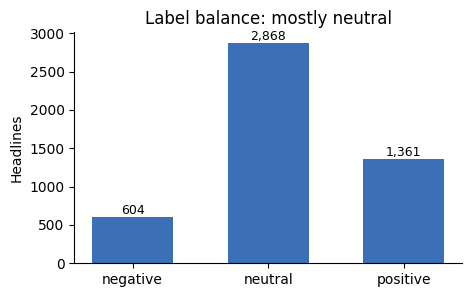

In [10]:
counts = df["sentiment"].value_counts().reindex(LABELS)
print((counts / counts.sum()).round(3))

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(counts.index, counts.values, color="#3b6fb6", width=0.6)
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
ax.set_title("Label balance: mostly neutral")
ax.set_ylabel("Headlines")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

            count  mean   std  min   25%   50%   75%   max
sentiment                                                 
negative    604.0  23.9   9.9  5.0  17.0  22.0  30.0  56.0
neutral    2868.0  22.1   9.8  2.0  15.0  21.0  28.0  81.0
positive   1361.0  24.7  10.1  5.0  17.0  23.0  31.0  57.0


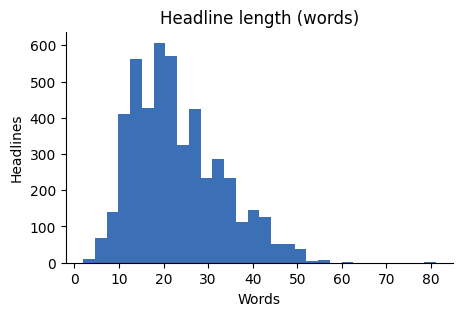

In [11]:
df["words"] = df["headline"].str.split().str.len()
print(df.groupby("sentiment")["words"].describe().round(1))

fig, ax = plt.subplots(figsize=(5, 3))
ax.hist(df["words"], bins=30, color="#3b6fb6")
ax.set_title("Headline length (words)")
ax.set_xlabel("Words")
ax.set_ylabel("Headlines")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

In [12]:
# Fixed seed, stratified. Few-shot examples and the supervised baseline
# use only `train`; `test` is never shown to a model before scoring.
train, test = train_test(df, n=300)
test.to_csv("data/kaggle/test_sample.csv", index=False)
print("Train:", len(train), "| Test:", len(test))
test["sentiment"].value_counts()


Train: 4533 | Test: 300


,count
sentiment,
neutral,178
positive,84
negative,38


## A3. Classifier evaluation: keyword baseline vs LLM

The LLM classifier is scored on the fixed 300-sentence held-out sample
with a sentiment-only prompt. The live news chain uses a longer prompt
that also asks for relevance, but the PhraseBank sentences have no target
company, so that instruction would only add noise here. Because LLM
output varies between runs (about 2 points of accuracy at n = 300), the
score reported here is the mean of three runs. A4 adds the majority vote
across the same three runs, which A5 uses as the primary metric.

In [13]:
from src.chains.kaggle import keyword_baseline, score, to_articles
from src.chains.news_chain import (
    CLASSIFY_SENTIMENT_SYSTEM,
    classify,
    coverage,
)

METRICS = ("accuracy", "macro_f1")
N_RUNS = 3  # LLM output varies run to run; report the mean, not one draw

keyword_pred = list(test["headline"].map(keyword_baseline))
base = score(test["sentiment"], keyword_pred)
print("Keyword baseline:", {k: base[k] for k in METRICS})

articles = to_articles(test)
runs, zero_preds = [], []
for r in range(N_RUNS):
    labels = classify(articles, system=CLASSIFY_SENTIMENT_SYSTEM)
    missing = coverage(labels, articles)["missing_ids"]
    pred = [
        labels.get(i, {}).get("sentiment", "neutral")
        for i in range(len(test))
    ]
    zero_preds.append(pred)
    runs.append(score(test["sentiment"], pred))
    print(
        f"LLM run {r + 1}:",
        {k: runs[-1][k] for k in METRICS},
        f"| unlabeled: {len(missing)}",
    )

mean = {k: round(sum(s[k] for s in runs) / N_RUNS, 3) for k in METRICS}
print("LLM mean of", N_RUNS, "runs:", mean)

llm = runs[-1]  # last run's per-class report and confusion matrix
print(llm["report"])


Keyword baseline: {'accuracy': 0.687, 'macro_f1': 0.575}
LLM run 1: {'accuracy': 0.833, 'macro_f1': 0.837} | unlabeled: 0
LLM run 2: {'accuracy': 0.823, 'macro_f1': 0.832} | unlabeled: 0
LLM run 3: {'accuracy': 0.843, 'macro_f1': 0.849} | unlabeled: 0
LLM mean of 3 runs: {'accuracy': 0.833, 'macro_f1': 0.839}
              precision    recall  f1-score   support

    negative       0.92      0.92      0.92        38
     neutral       0.87      0.87      0.87       178
    positive       0.75      0.76      0.76        84

    accuracy                           0.84       300
   macro avg       0.85      0.85      0.85       300
weighted avg       0.84      0.84      0.84       300



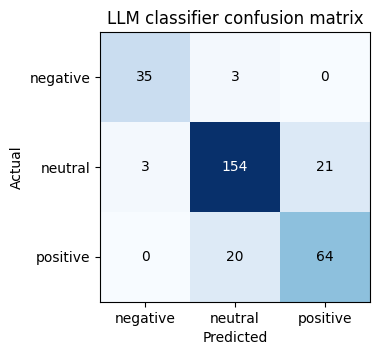

In [14]:
cm = llm["confusion"]

fig, ax = plt.subplots(figsize=(4, 3.5))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(3), LABELS)
ax.set_yticks(range(3), LABELS)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
for i in range(3):
    for j in range(3):
        color = "white" if cm[i, j] > cm.max() / 2 else "black"
        ax.text(j, i, cm[i, j], ha="center", va="center", color=color)
ax.set_title("LLM classifier confusion matrix")
plt.show()

## A4. Classifier diagnostics: supervised baseline, few-shot prompts, agreement

Three checks on the zero-shot LLM classifier above:

1. **A supervised baseline.** A pretrained model can be applied to a task
   by prompting it or by training on labeled data (Jurafsky & Martin, 2026,
   Section 9.4). TF-IDF with logistic regression, trained on the same
   train split, stands in for the second, so the LLM is compared with a
   model that learned from these labels and not only with keywords.
2. **Few-shot prompting.** Two demonstrations per label are added to the
   prompt, drawn from the train split, as Brown et al. (2020, Section 2.4)
   draw conditioning examples from the training set and never from the
   test set. Demonstrations come from sentences every annotator agreed
   on, and K is fixed in advance rather than tuned on the test set. The
   sentiment definition in the prompt now restates the PhraseBank
   annotation guideline: judge only what the sentence states, from an
   investor's view of the stock price (Malo et al., 2014).
3. **Majority vote across runs.** The three runs per prompt are combined
   by majority vote, the self-consistency idea of keeping the answer most
   samples agree on (Wang et al., 2023). It reuses the runs already made,
   so it adds no API calls.

Finally, accuracy is broken down by annotator agreement. If the model is
far more accurate where every annotator agreed, many remaining "errors"
are sentences that people also labeled differently.


In [15]:
from src.chains.kaggle import (
    fewshot_examples,
    load_agreement,
    majority_vote,
    score_by_agreement,
    tfidf_baseline,
)

agreement = load_agreement()
print("Sentences with an agreement band:", len(agreement))

tfidf_pred = tfidf_baseline(train, test)

examples = fewshot_examples(train, per_label=2, agreement=agreement)
print("Few-shot demonstrations (train split, unanimous labels):")
for text, label in examples:
    print(f"  {label:>8}: {text[:90]}")

few_preds = []
for r in range(N_RUNS):
    labels = classify(
        articles, system=CLASSIFY_SENTIMENT_SYSTEM, examples=examples
    )
    few_preds.append(
        [
            labels.get(i, {}).get("sentiment", "neutral")
            for i in range(len(test))
        ]
    )

candidates = {
    "keyword": [keyword_pred],
    "tf-idf + logistic regression": [tfidf_pred],
    "LLM zero-shot": zero_preds,
    "LLM few-shot": few_preds,
}
rows = []
for name, preds in candidates.items():
    per_run = [score(test["sentiment"], p) for p in preds]
    vote = score(test["sentiment"], majority_vote(preds))
    rows.append(
        {
            "classifier": name,
            "runs": len(preds),
            **{
                f"{m} (mean)": round(
                    sum(s[m] for s in per_run) / len(preds), 3
                )
                for m in METRICS
            },
            **{f"{m} (vote)": vote[m] for m in METRICS},
        }
    )
comparison = pd.DataFrame(rows)
comparison


Sentences with an agreement band: 4835
Few-shot demonstrations (train split, unanimous labels):
  negative: The fair value of the company 's investment properties went down to EUR 2.768 billion at t
  negative: At 1411 CET , ArcelorMittal had lost 7.26 % to EUR 17.38 on Euronext Paris , coming at the
   neutral: Cramo Plc is a service company specialising in construction machinery and equipment rental
   neutral: The building will house product development and test laboratories .
  positive: Section : Regional News - The demand in Finnair 's Asian traffic , measured in passenger k
  positive: The Group also has a strong global position in other fishing categories .


,classifier,runs,accuracy (mean),macro_f1 (mean),accuracy (vote),macro_f1 (vote)
0,keyword,1,0.687,0.575,0.687,0.575
1,tf-idf + logistic regression,1,0.793,0.771,0.793,0.771
2,LLM zero-shot,3,0.833,0.839,0.853,0.863
3,LLM few-shot,3,0.831,0.838,0.837,0.846


Test sentences per band: {'100%': 149, '75-99%': 71, '66-74%': 42, '50-65%': 38}


classifier,LLM few-shot (vote),LLM zero-shot (vote),tf-idf + LR
band,,,
100%,0.960,0.960,0.899
75-99%,0.873,0.915,0.775
66-74%,0.714,0.714,0.762
50-65%,0.421,0.474,0.447


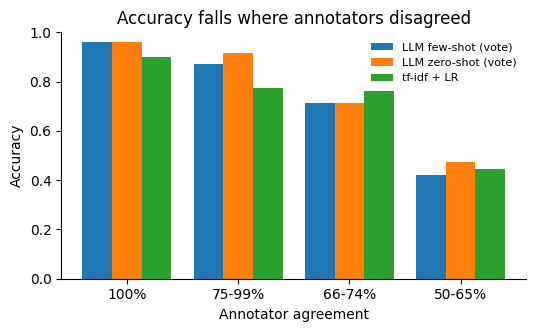

In [16]:
final_preds = {
    "tf-idf + LR": tfidf_pred,
    "LLM zero-shot (vote)": majority_vote(zero_preds),
    "LLM few-shot (vote)": majority_vote(few_preds),
}
by_band = pd.concat(
    score_by_agreement(test, p, agreement).assign(classifier=name)
    for name, p in final_preds.items()
)
band_order = ["100%", "75-99%", "66-74%", "50-65%"]
acc = by_band.pivot(index="band", columns="classifier", values="accuracy")
acc = acc.reindex([b for b in band_order if b in acc.index])
counts = by_band.drop_duplicates("band").set_index("band")["n"]
print("Test sentences per band:", counts.reindex(acc.index).to_dict())
display(acc)

fig, ax = plt.subplots(figsize=(6, 3.2))
width = 0.8 / len(acc.columns)
for j, name in enumerate(acc.columns):
    offset = (j - (len(acc.columns) - 1) / 2) * width
    xs = [i + offset for i in range(len(acc))]
    ax.bar(xs, acc[name], width, label=name)
ax.set_xticks(range(len(acc)), acc.index)
ax.set_xlabel("Annotator agreement")
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1)
ax.set_title("Accuracy falls where annotators disagreed")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8)
plt.show()


### Interpretation of A4: financial sentiment classification

On the 300-sentence held-out set, the zero-shot LLM majority vote
recorded the highest macro-F1, **0.863**, with the few-shot vote at
**0.846**, TF-IDF logistic regression at **0.771** and the keyword
baseline at **0.575**. Both LLM prompts beat the supervised baseline by
a wide margin; the gap between the two prompts (0.017) is smaller than
the run-to-run variation seen in A3 and in earlier runs, where few-shot
led, so it should not be read as an established difference.

Accuracy depends on how much the annotators agreed. Where all
annotators agreed, both LLM prompts reached **96.0%**; in the 75–99%
band zero-shot was more accurate (91.5% vs 87.3%); in the lowest band
(50–65% agreement) accuracy fell to **42–47%** for every classifier,
including TF-IDF. Many of the remaining errors are therefore sentences
that people also labeled differently (Malo et al., 2014), which limits
what any classifier can achieve on this benchmark.

## A5. Metrics, provenance and run-to-run variation

The table above reports the mean of three LLM classifications per
prompt and their majority vote. The majority vote follows the
self-consistency idea of keeping the answer most samples agree on
(Wang et al., 2023); few-shot demonstrations are drawn from the training
split only, as Brown et al. (2020) draw conditioning examples from
training data and never from the test set. The supervised baseline is
TF-IDF with logistic regression, the classical alternative to prompting
a pretrained model (Jurafsky & Martin, 2026).

The Financial PhraseBank (Malo et al., 2014) is public and may overlap
with model pretraining data, so these scores describe performance on
this benchmark, not verified generalization to unseen current news. The
October 14 and October 18 runs used different data cleaning and prompts
and are not a controlled comparison with this one. Across four runs
with identical code and data on October 19, the LLM's majority-vote
macro-F1 ranged from 0.827 to 0.863, and zero-shot and few-shot
prompting changed places from run to run; that spread is the run-to-run
variation against which differences in the table should be read.

In [17]:
# Directly summarize this notebook's current classification results.
metric_cols = ["classifier", "accuracy (mean)", "macro_f1 (mean)"]
display(
    comparison[metric_cols].sort_values("macro_f1 (mean)", ascending=False)
)

best = comparison.loc[comparison["macro_f1 (mean)"].idxmax()]
print("Highest observed macro-F1:", best["classifier"],
      "| score:", round(float(best["macro_f1 (mean)"]), 3))
print(
    "Accuracy by agreement level is reported in the preceding "
    "table and plot."
)


,classifier,accuracy (mean),macro_f1 (mean)
2,LLM zero-shot,0.833,0.839
3,LLM few-shot,0.831,0.838
1,tf-idf + logistic regression,0.793,0.771
0,keyword,0.687,0.575


Highest observed macro-F1: LLM zero-shot | score: 0.839
Accuracy by agreement level is reported in the preceding table and plot.


# Part B. Autonomous research workflow

## Agent Design and Workflows

EquityAgent is a LangGraph state graph (`src/graph.py`). One research
request passes through planning, routing, specialist data gathering,
verification, synthesis, iterative evaluation and revision, reflection,
and memory. The three specialists are independent and run concurrently.

```text
Ticker → Plan → Route → Specialists → Verify → Synthesize → Evaluate ⇄ Optimize
                                                                 |
                                                          Final selection
                                                                 ↓
                                                         Reflect → Memory
```

| Stage | Implementation | Pattern | Evidence below |
|---|---|---|---|
| Planning and routing | `src/agents/planner.py`, `router.py` | Plan then route each step to a specialist | B2, B4 |
| Specialists and tools | `src/agents/specialists.py`, `src/tools/` | Reasoning interleaved with tool calls (Yao et al., 2023); filing retrieval (Lewis et al., 2020) | B3, B6 |
| News prompt chain | `src/chains/news_chain.py` | Ingest → preprocess → classify → extract → summarize | B5 |
| Data verification | `src/agents/verifier.py` | Rule-based check of every figure against raw tool data | B6b |
| Synthesis | `src/agents/synthesizer.py` | Brief written only from the findings | B8 |
| Evaluation and revision | `src/agents/evaluator.py`, `evaluation_pipeline.py` | Generate → evaluate → refine (Madaan et al., 2023) with a quality gate | B7 |
| Reflection and memory | `src/memory/store.py` | Verbal self-review stored as lessons for later runs (Shinn et al., 2023) | B9, B10 |

The demonstration below uses NVDA and starts from empty experiment-local
memory, so the first run is a true first run. A second run on the same
ticker then shows the planner reading the stored lessons. Clearing the
notes file is deliberate for this controlled experiment and does not
change files in the repository.

## B1. Setup check: every tool returns data

One call per tool per ticker, plus the number of 10-K chunks indexed for
retrieval. `ok` means the tool returned data; any other value is the
error it raised.

In [18]:
print("Chunks indexed:", index_filings(TICKERS))
pd.DataFrame({t: quick_smoke(t) for t in TICKERS})

Chunks indexed: 566


,NVDA,JPM,XOM
get_price_history,ok,ok,ok
get_key_stats,ok,ok,ok
get_financials,ok,ok,ok
get_macro_snapshot,ok,ok,ok
get_news,ok,ok,ok


## B2. Research plan

The planner reads memory first. On the first run of a ticker there are no
notes; later runs show the lessons it used.

In [19]:
# Start from empty memory so the first run below is a true first run.
store.NOTES_PATH.unlink(missing_ok=True)
print("Lessons in memory:", len(store.load_notes()))


Lessons in memory: 0


In [20]:
TICKER = "NVDA"
notes_before = store.load_notes()

report, trace, state = run_agent(TICKER, reviewed_evaluation=True)

print("Sector:", state["sector"])
print("Hypothesis:", state["plan"].hypothesis)
show.plan_table(trace)

Sector: Technology
Hypothesis: Can Nvidia sustain its premium valuation given AI-driven growth expectations against risks from customer concentration, export controls, and cyclical semiconductor demand?


,id,task,tool,purpose,priority
0,1,"Retrieve current valuation multiples, margins, ROE, and analyst price targets",get_key_stats,Establish baseline valuation and how much growth is already priced in relative to peers,high
1,2,"Pull annual income statement, balance sheet, and cash flow for the last several years",get_financials,"Assess revenue growth trajectory, margin trends, R&D investment, and balance sheet strength to fund growth",high
2,3,"Analyze 5-year price history for returns, volatility, beta vs SPY, and moving averages",get_price_history,"Understand market behavior, momentum, and risk profile relative to the broader market",high
3,4,"Search latest 10-K risk factors for customer concentration, export control, and supply chain risks",search_filings,"Identify key disclosed risks such as reliance on TSMC, China export restrictions, and hyperscaler customer concentra...",high
4,5,Fetch recent news headlines on Nvidia,get_news,"Capture latest developments on AI chip demand, export policy changes, competitive threats, and earnings reactions",high
5,6,"Get current macro snapshot including interest rates, CPI, and GDP trends",get_macro_snapshot,Contextualize how macro conditions like rate levels and economic growth could affect capex spending on AI infrastruc...,medium
6,7,Search 10-K MD&A for management commentary on AI data center demand and competitive positioning,search_filings,"Gain management's own view on growth sustainability and competitive dynamics versus AMD, custom silicon, and other e...",medium


In [21]:
show.memory_read(trace)

No prior lessons: first run for this ticker and sector.


,lesson


## B3. Tool calls (dynamic tool use)

The plan, not the code, decides which tools run and with what query.
The three specialists run in parallel, so the log is grouped by the
specialist (`route`) that made each call.


In [22]:
show.tool_log(trace)

,route,tool,args,ok,rows,error
0,earnings,get_key_stats,{},True,14,None
1,earnings,get_financials,{},True,12,None
2,earnings,search_filings,"{'query': 'Search latest 10-K risk factors for customer concentration, export control, and supply chain risks'}",True,3,None
3,earnings,search_filings,{'query': 'Search 10-K MD&A for management commentary on AI data center demand and competitive positioning'},True,3,None
4,market,get_price_history,{},True,7,None
5,market,get_macro_snapshot,{},True,5,None
6,news,get_news,{},True,99,None


## B4. Routing decisions

Each plan step is assigned to the earnings, market or news specialist,
with the router's stated reason. The specialist, not the planner,
decides how to carry the step out.

In [23]:
show.routing_table(trace)

,step_id,route,reason
0,1,earnings,"This task focuses on company valuation multiples and financial ratios such as margins and ROE, with analyst price ta..."
1,2,earnings,"Annual income statements, balance sheets, and cash flow statements are financial-statement data used to assess growt..."
2,3,market,"This task analyzes five-year price performance, volatility, beta versus SPY, and moving averages, which are market a..."
3,4,earnings,"This task requires searching and interpreting the latest 10-K risk-factor disclosures, including customer concentrat..."
4,5,news,"This task requests recent Nvidia headlines about demand, export policy, competition, and earnings reactions."
5,6,market,"This task asks for current interest rates, CPI, and GDP trends to assess macroeconomic conditions affecting AI infra..."
6,7,earnings,"This task analyzes management commentary in a 10-K MD&A on demand sustainability and competitive positioning, which ..."


## B5. News prompt chain: output of each step

The news specialist runs a five-step prompt chain, and the output of
every step is printed: ingest (headlines fetched), preprocess (duplicates,
non-news and stale items removed), classify (topic, sentiment and
relevance per article), extract (entities, figures and events), and
summarize (the digest).

The digest's `net_sentiment` is not the model's opinion: the chain counts
the per-article labels from the classify step and applies majority rule
with a 15-point margin (`sentiment_counts` is printed with the summary).
Empty `figures` lists in the extract step are expected for headline-only
items; the extractor only reports numbers that appear in the text.

In [24]:
show.news_chain_steps(trace)


=== INGEST ===
{
 "n": 99,
 "sample": [
  "Nvidia says its new AI safety platform can contain rogue agents within \u2018milliseconds\u2019",
  "Nvidia launches agent safety platform backed by over 100 companies",
  "Nvidia commits $250M of compute to UK AI safety research",
  "Nvidia-backed Reflection unveils Beam, its first open-weight model",
  "Nvidia adds a record $150bn to its share buyback"
 ],
 "earliest": "2026-09-19T10:32:00Z",
 "latest": "2026-10-18T16:03:01Z"
}

=== PREPROCESS ===
{
 "n_in": 99,
 "n_out": 97,
 "duplicate": 0,
 "non_news": 1,
 "stale": 1,
 "no_mention": 0
}

=== CLASSIFY ===
{
 "0": {
  "id": 0,
  "topic": "product",
  "sentiment": "neutral",
  "relevance": "high"
 },
 "1": {
  "id": 1,
  "topic": "product",
  "sentiment": "positive",
  "relevance": "high"
 },
 "2": {
  "id": 2,
  "topic": "other",
  "sentiment": "neutral",
  "relevance": "high"
 },
 "3": {
  "id": 3,
  "topic": "product",
  "sentiment": "neutral",
  "relevance": "high"
 },
 "4": {
  "id": 4

## B6. Specialist findings

One finding per specialist: a summary, key figures and risks written
only from that specialist's tool output. B6b checks these figures next,
before any brief is written.

In [25]:
show.findings_table(trace)

,route,summary,key_figures,risks
0,market,"NVDA closed at $217.09, trading below its 50-day SMA ($222.94) but above its 200-day SMA ($203.12), reflecting a nea...","[Last close: $217.09, 1-month return: -2.33%, 1-year return: 19.4%, Annualized volatility: 37.28%, Beta vs SPY: 2.12...","[High beta (2.129) implies amplified downside in market sell-offs, Price trading below its 50-day moving average sig..."
1,earnings,"NVIDIA's FY2026 (ended Jan 31, 2026) revenue surged to $215.94B, up ~65% from $130.50B in FY2025, with operating inc...","[Market Cap: $5,242,072,072,192, Trailing P/E: 27.45x; Forward P/E: 13.64x, Price/Book: 22.89x, Profit Margin (TTM):...",[Customer concentration: 'A significant amount of our revenue stems from a limited number of partners and distributo...
2,news,"Sentiment is neutral, reflecting the clear majority of neutral coverage (63 articles, versus 14 positive and 14 nega...","[Nvidia authorized an additional $150 billion in share buybacks, a major capital-return signal. [4][9], Nvidia launc...","[A report alleged that a California man smuggled $300 million in Nvidia chips to China, underscoring export-control ..."


## B6b. Data verification specialist

Before any brief is written, a separate verification agent
(`src/agents/verifier.py`) re-reads the raw tool output the specialists
received and checks every financial figure in their findings. A figure is
**confirmed** if it equals a raw value, or one computed from raw values
(year-over-year change, margin, ratio as a percent, macro change), at the
precision written; **contradicted** if the finding names a metric and fiscal
year whose raw value differs; and **not found** otherwise, which flags it
for attribution rather than proving it wrong.

The agent is rule-based, so its checks are reproducible and independent of
the models that wrote the findings. Its corrections and flags travel with
the findings to the synthesizer and the evaluator. News findings summarize
article text, which the verifier does not hold, so they are not checked.

In [26]:
# Verification specialist: findings checked against raw data.
verification = pd.DataFrame(state["verification"])
display(verification[["route", "status", "checked", "confirmed",
                      "not_found", "contradicted"]])
for row in state["verification"]:
    if row["corrections"]:
        print(f"{row['route']} corrections: {row['corrections']}")
    if row["not_found_figures"]:
        print(f"{row['route']} not found in raw data: "
              f"{row['not_found_figures']}")
    if row["note"]:
        print(f"{row['route']}: {row['note']}")


,route,status,checked,confirmed,not_found,contradicted
0,earnings,checked,41,41,0,0
1,market,checked,23,23,0,0
2,news,not_checked,0,0,0,0


news: News figures come from article text, which the verifier does not hold.


## B7. Evaluator–Optimizer: generate, evaluate, and refine

The research agent synthesizes an initial brief, scores five criteria from
1 to 5 (**completeness, evidence, accuracy, balance, and clarity**), then
uses specific evaluation feedback to revise the brief, following the
generate–evaluate–refine loop of Self-Refine (Madaan et al., 2023). Claude
Sonnet 5 writes and optimizes the drafts; GPT-6 Sol evaluates them. These
are distinct model roles, rather than two independent scoring models.

The **baseline acceptance policy** requires an average of at least 4.0 after
the minimum revision count. The **enhanced quality policy** additionally
requires accuracy and evidence scores of at least 4/5, blocks acceptance on
recognized numerical contradictions, records unresolved figures, and can
select the highest scoring acceptable revision.

| Acceptance rule | Baseline | Enhanced policy |
|---|---|---|
| Minimum average | 4.0 | 4.0 |
| Minimum accuracy | No separate floor | 4 / 5 |
| Minimum evidence | No separate floor | 4 / 5 |
| Minimum revision rounds | 1 | 1 |
| Maximum evaluated drafts | 3 | 3 |
| Contradictions found by limited numeric parser | Not a separate gate | Block acceptance |
| Final draft choice | Last evaluated revision | Best accepted revision |

Figures are compared at the precision the brief writes them, so rounding
("$215.9B" for "$215,938M") is not a contradiction.

Unrecognized or unsupported claims are **unverified**, not proven correct.
The parser covers only a narrow subset of financial prose; discrepancies
require human review. Exhausting the evaluation budget does not constitute
acceptance.

In [27]:
show.evaluation_history(state)

,iteration,average,completeness,evidence,accuracy,balance,clarity
0,0,4.4,5,4,5,5,3
1,1,4.6,4,5,5,5,4


In [28]:
show.critiques(state)


Iteration 0 (avg 4.4):
  - Shorten the repeated thesis, bull/bear points, fundamentals, and conclusion so a portfolio manager can identify the stance and key risks in two minutes.
  - Remove “beyond current guidance”: the findings provide no guidance against which to assess the reported SpaceX talks.
  - Qualify “industry-leading” margins and a “dominant competitive position,” or add comparative evidence; neither claim is established by the findings.
  - Describe the buyback as an additional $150B authorization, rather than implying it is an entirely new program.
  - Keep the inventory concern explicitly attributed to critical commentary; the findings do not establish channel inventory buildup as fact.
  - Reconcile the thesis’s “high-conviction long” language with the conclusion’s more cautious, risk-aware stance.

Iteration 1 (avg 4.6):
  - Add the filing’s explicit risk that shortages of data-center capacity, energy, or customer capital could limit AI infrastructure demand.
  - Qua

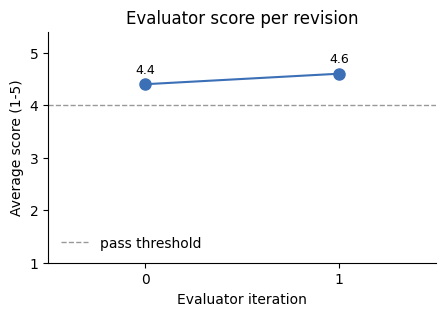

In [29]:
show.plot_scores(state)
plt.show()

In [30]:
# Summarize live rubric decisions and numeric audit coverage.
review_rows = []
for item in state["history"]:
    scores = item["scores"]
    review_rows.append({
        "iteration": item["iteration"],
        "average": item["average"],
        "accuracy": scores["accuracy"],
        "evidence": scores["evidence"],
        "passed": item.get("accepted", False),
        "selected": item.get("selected", False),
        "reason": ", ".join(item.get("failures", [])) or "none",
        "numeric_checked": item.get("numeric_checked", 0),
        "numeric_unverified": item.get("numeric_unverified", 0),
        "numeric_contradicted": item.get("numeric_contradicted", 0),
    })
review_df = pd.DataFrame(review_rows)
display(review_df[["iteration", "average", "accuracy", "evidence",
                   "passed", "selected", "reason"]])
display(review_df[["iteration", "numeric_checked", "numeric_unverified",
                   "numeric_contradicted"]])

print("Final decision:", "accepted" if state["accepted"] else "not accepted")
print("Selected revision:", state["selected_iteration"])
print("Selected rubric average:", state["evaluation"].average)
print("Numeric claims checked:", len(state["numeric_audit"].checks))

numeric_rows = state["numeric_audit"].rows()
if numeric_rows:
    display(pd.DataFrame(numeric_rows))
else:
    print("No claims matched the constrained numeric validator.")


,iteration,average,accuracy,evidence,passed,selected,reason
0,0,4.4,5,4,True,False,none
1,1,4.6,5,5,True,True,none


,iteration,numeric_checked,numeric_unverified,numeric_contradicted
0,0,3,0,0
1,1,1,0,0


Final decision: accepted
Selected revision: 1
Selected rubric average: 4.6
Numeric claims checked: 1


,kind,status,metric,period,observed,expected,reason,excerpt
0,reported,supported,free cash flow,None,96680000000.00,96680000000.00,matching_value_period_not_stated,Free cash flow of $96.68B


### Interpretation of B7: evaluation and iterative revision

The first NVDA draft scored **4.4/5** (completeness 5, evidence 4,
accuracy 5, balance 5, clarity 3). It met the score and accuracy
thresholds, but the policy requires at least one revision, and the
evaluator listed six fixable critiques, mostly about length and
unsupported comparative claims ("industry-leading" margins). The
revised draft scored **4.6/5** with evidence and accuracy both at 5 and
was accepted and kept. The numeric audit recognized three figures in
the first draft and one in the second (free cash flow of $96.68B), all
supported by the findings; no contradictions were found. Figures are
compared at the precision the brief writes them, so a rounded figure is
not a contradiction.

Before any draft was written, the data verification specialist (B6b)
checked all **64** figures in the earnings and market findings against
the raw tool data and confirmed every one; news findings, which
summarize article text, are not checked. The evaluator's three
critiques of the accepted draft were not revised further, because
acceptance ends the loop; they remain review points for a reader.

## B8. Final report

The draft the quality gate kept (see B7), rendered as the research
brief. A warning line appears above it if no draft was accepted.

In [31]:
if not state["accepted"]:
    print(
        "Quality criteria were not met; the following report is "
        "retained for diagnostic review."
    )
display(show.report_markdown(report))


# NVDA research brief

**Thesis:** NVDA posted explosive FY2026 growth (revenue +65.5% to \$215.94B, EPS \$4.90) with strong margins, cash flow, and an additional \$150B buyback authorization. Shares sit below the 50-day SMA amid high volatility (37.3%), beta 2.13, rising 10-year yields (5.09%), and export-control/supply-chain risks. Valuation (13.6x forward P/E) looks reasonable given growth. Net: constructive but risk-aware long, not unqualified bullishness.

## Bull case
- FY2026 revenue grew 65.5% YoY to \$215.94B with 60.4% operating margin and 55.6% net margin
- Forward P/E of 13.6x vs trailing 27.4x, with 'strong buy' consensus and \$328.72 mean target (59 analysts)
- Free cash flow of \$96.68B and low leverage (debt-to-equity 0.07x) provide flexibility, plus an additional \$150B buyback authorization
- ROE of 117.2% and TTM profit margin of 63.7% indicate strong profitability, though no peer comparison is available to confirm competitive positioning
- Reported SpaceX financing talks (~\$40B) for Nvidia AI hardware signal potential demand, though still unconfirmed

## Bear case
- Stock trades below its 50-day SMA (\$222.94) with -2.33% 1-month return, despite remaining above the 200-day SMA (\$203.12)
- High beta (2.13) and 37.3% annualized volatility imply outsized downside risk in market corrections
- Rising 10-year Treasury yield (5.09%, up ~110bps YoY) could pressure high-multiple growth valuations
- Export controls remain material: April 2025 H20 restriction caused a \$4.5B inventory charge; smuggling enforcement and further China curbs are ongoing risks
- Customer concentration, supply-chain dependency, and product transition risk (Blackwell Ultra/GB300, Rubin) could drive revenue volatility; critical commentary (unverified) also flags possible channel inventory buildup

## Fundamentals
FY2026 revenue reached \$215.94B (+65.5% YoY), operating income \$130.39B (60.4% margin, down from 62.4%), and net income \$120.07B vs \$72.88B. Diluted EPS rose to \$4.90 from \$2.94. Total assets grew to \$206.80B and equity to \$157.29B, with total debt of just \$11.04B (debt-to-equity 0.07x). Operating cash flow was \$102.72B and free cash flow \$96.68B, up sharply from FY2025 despite capex nearly doubling to \$6.04B. Valuation: trailing P/E 27.4x, forward P/E 13.6x, price-to-book 22.9x, TTM margin 63.7%, ROE 117.2%, dividend yield 0.47%. Analyst consensus: 'strong buy,' mean target \$328.72 (59 analysts).

## News and catalysts
Sentiment is largely neutral (63 neutral vs 14 positive, 14 negative). Positive catalysts: an additional \$150B buyback authorization and reports of SpaceX seeking ~\$40B in financing to purchase Nvidia AI hardware (unconfirmed), alongside a record share price partly linked to the buyback. Nvidia also launched an AI-agent safety platform, drawing mostly neutral coverage. Offsetting risks: an alleged \$300M chip-smuggling case to China, critical commentary alleging large warehouse inventory buildup (unverified), and a high-severity vulnerability in Nvidia's GPU monitoring software.

## Market and macro
NVDA closed at \$217.09, below its 50-day SMA (\$222.94) but above its 200-day SMA (\$203.12), indicating a near-term pullback within a longer-term uptrend. 1-year return is 19.4%, 1-month return -2.33%. Annualized volatility is 37.3% with beta 2.13 vs SPY. Macro backdrop: CPI up 3.7% YoY, Fed funds easing to 3.75% from 4.22%, yet the 10-year Treasury yield rose to 5.09% from 3.99%. Real GDP growth ~2.2%, unemployment down to 4.2% from 4.4%.

## Conclusion
Fundamentals remain strong — rapid growth, high margins, robust free cash flow, and a reasonable forward multiple — supported by strong-buy consensus and a sizable buyback. But near-term technical weakness, high volatility/beta, rising long yields, and unresolved export-control and supply-chain risks warrant a constructive but risk-aware stance rather than high-conviction bullishness. Investors should monitor export-policy developments and inventory/demand signals. This is analysis, not investment advice.

*Analysis only; not investment advice.*

## B9. Reflection (self-assessment of output and process)

The agent's review of its own run: the weakest section, claims the
findings do not support, data that was missing, tools that failed, what
to change next time, and the lessons it will store for future runs.

In [32]:
show.reflection_view(state)

{'weakest_section': 'Bull case',
 'unsupported_claims': ['SpaceX ~$40B financing talks for Nvidia AI hardware are presented as a bull signal despite being explicitly labeled unconfirmed reports',
  'Critical commentary alleging large warehouse inventory buildup is cited in the bear case despite being flagged unverified, with no corroborating inventory-turnover or days-sales-outstanding data to confirm or refute it',
  "ROE of 117.2% and profit margin of 63.7% are called 'strong profitability' without any peer/sector comparison to substantiate relative competitive positioning",
  "'Strong buy' consensus and $328.72 mean target are presented without distribution of individual analyst targets or recent revision trends, which would show whether sentiment is improving or deteriorating"],
 'missing_data': ['No segment-level revenue breakdown (data center vs. gaming vs. automotive/other) to assess concentration risk or growth drivers within the AI hardware story',
  'No peer/competitor valuat

## B10. Memory: what this run taught the agent

The lessons from B9 are written to `memory/notes.json`. A second run on
the same ticker then shows the planner reading them, and its full plan
is printed so the influence of each lesson can be read in the task and
purpose columns.

In [33]:
show.memory_diff(trace)

,ticker,sector,date,lesson
0,NVDA,Technology,2026-10-19,"For AI/semiconductor companies, pull segment revenue breakdown (data center/gaming/auto) to properly assess customer..."
1,NVDA,Technology,2026-10-19,"When citing profitability ratios (ROE, margins) as a bull-case strength, pull at least one peer's equivalent stats t..."
2,NVDA,Technology,2026-10-19,"Flag unverified news items (unconfirmed deals, anonymous critical commentary) with a visible confidence tag in the b..."
3,NVDA,Technology,2026-10-19,"For high-beta/high-volatility names, supplement historical volatility with options-implied volatility or analyst est..."


In [34]:
report2, trace2, state2 = run_agent(TICKER, reviewed_evaluation=True)
print("Lessons the planner read on run 2:")
display(show.memory_read(trace2))
print("Run 1 steps:", [s.tool for s in state["plan"].steps])
print("Run 2 steps:", [s.tool for s in state2["plan"].steps])
print("Run 1 final score:", state["evaluation"].average,
      "| Run 2 final score:", state2["evaluation"].average)

Lessons the planner read on run 2:


,ticker,sector,date,lesson
0,NVDA,Technology,2026-10-19,"For AI/semiconductor companies, pull segment revenue breakdown (data center/gaming/auto) to properly assess customer..."
1,NVDA,Technology,2026-10-19,"When citing profitability ratios (ROE, margins) as a bull-case strength, pull at least one peer's equivalent stats t..."
2,NVDA,Technology,2026-10-19,"Flag unverified news items (unconfirmed deals, anonymous critical commentary) with a visible confidence tag in the b..."
3,NVDA,Technology,2026-10-19,"For high-beta/high-volatility names, supplement historical volatility with options-implied volatility or analyst est..."


Run 1 steps: ['get_key_stats', 'get_financials', 'get_price_history', 'search_filings', 'get_news', 'get_macro_snapshot', 'search_filings']
Run 2 steps: ['get_key_stats', 'get_key_stats', 'get_financials', 'search_filings', 'search_filings', 'get_price_history', 'get_news', 'get_macro_snapshot']
Run 1 final score: 4.6 | Run 2 final score: 4.6


In [42]:
show.plan_table(trace2)

,id,task,tool,purpose,priority
0,1,"Pull Nvidia's key valuation and profitability stats including market cap, P/E, P/B, margins, ROE, and analyst price ...",get_key_stats,Establish baseline valuation and profitability metrics to assess if current price reflects fundamentals,high
1,2,"Pull key stats for a peer (e.g., AMD or AVGO) to benchmark Nvidia's margins and ROE",get_key_stats,"Per lesson learned, relative profitability claims require peer comparison rather than standalone assertion",high
2,3,"Retrieve annual income statement, balance sheet, and cash flow data for Nvidia",get_financials,"Assess revenue growth trajectory, margin trends, cash generation, and balance sheet strength to support or refute gr...",high
3,4,"Search latest 10-K for segment revenue breakdown across data center, gaming, and automotive, plus customer concentra...",search_filings,"Per lesson learned, segment and customer concentration data is critical for assessing dependency risk on hyperscaler...",high
4,5,"Search 10-K Risk Factors and MD&A for export controls, China restrictions, and supply chain risks",search_filings,Identify regulatory and geopolitical risks that could materially impact Nvidia's addressable market,high
5,6,"Pull 5-year daily price history to calculate volatility, beta vs SPY, and recent moving average trends",get_price_history,"Quantify historical market risk and momentum, to be supplemented with implied volatility context per lesson learned",medium
6,7,Retrieve recent news headlines from the last 30 days on Nvidia,get_news,"Surface recent catalysts, deals, or controversies; per lesson learned, flag any unconfirmed items with confidence ta...",medium
7,8,"Pull current macro snapshot including CPI, Fed funds rate, 10-year yield, and GDP trends",get_macro_snapshot,Assess macro backdrop affecting rate-sensitive tech valuations and capex cycles for AI infrastructure spending,medium


# Part C. Evaluation and comparative analysis

## Evaluation and Iteration

Part B showed one evaluate-and-revise loop in detail. This part measures
the agent against simpler alternatives and tests what its quality
controls change. Every comparison uses the same five-criterion rubric
(completeness, evidence, accuracy, balance, clarity) scored by the same
evaluator model, and every brief is graded against the same collected
findings, so the comparisons differ only in what the writer was given
and how the draft was produced.

The three experiments answer different questions and should not be
combined into one causal claim:

- **C1** compares the agent with a no-tools baseline (the value of
  evidence plus workflow), with an evidence-matched baseline (the value
  of the workflow alone), and with itself with memory off (the effect of
  stored lessons). The memory comparison uses separate live runs, so
  model and data variation remain confounders.
- **C2** replays two acceptance policies on the **same sequence of
  observed rubric scores**, so it isolates the stopping rule.
- **C3** states the limitations.

Two independent checks accompany the rubric scores: the data
verification specialist's count of figures confirmed against raw tool
data (B6b), and the numeric audit's checks of recognized figures in the
brief against the findings (B7). Both cover only the figures their
parsers recognize.

## C1. Report quality, numerical evidence, and memory

Four descriptive analyses are reported for NVDA, JPM and XOM:

1. **No-tools baseline versus research agent.** For each ticker, a
   single prompt produces a brief with no findings, no plan and no
   revision. Both briefs are graded against the same collected findings.
   This measures the combined effect of research evidence and the agent
   workflow, not one component in isolation.
2. **Evidence-matched baseline versus research agent.** A single-pass
   brief is written from the *same findings* the agent used, with no
   planning, revision or quality gate, and graded the same way. The gap
   to this baseline isolates what the evaluate-and-revise loop and the
   quality gate add beyond access to the evidence. This is the fairer of
   the two comparisons.
3. **Figure checks.** Three counts are reported per ticker: figures in
   the specialists' findings that the verification specialist confirmed
   against raw tool data (`figures_checked`, `figures_confirmed`,
   `figures_corrected`); recognized figures in the kept brief that the
   numeric audit checked against the findings (`numeric_checked`,
   `numeric_contradicted`, `numeric_unverified`); and an exact-string
   count of figures in each brief that appear verbatim in no finding
   (`unsupported_*`). The last measure counts rounding, scaling and unit
   differences as unsupported, so it is a review aid, not a fact check.
4. **Memory on versus off.** The same ticker is run with stored lessons
   hidden from the planner and then with them available. Plan length,
   lessons read and rubric scores are compared. Because these are
   separate live runs, LLM and data variation remain confounders.

Each agent run uses the reviewed evaluation policy (B7). The table
below is written to `Results/table1_integrated_live_run.csv` and is the
source for every figure quoted in the interpretation; no values are
carried over from earlier runs.

In [35]:
from src.evaluation_lead_benchmarks import matched_baseline_brief

rows = []
for t in TICKERS:
    rep, tr, st = run_agent(t, reviewed_evaluation=True)
    base = baseline_brief(t)
    base_score = score_against_findings(base, st["findings"])
    findings = st["findings"]
    # Same findings, one pass, no revision or gate.
    matched = matched_baseline_brief(t, findings)
    matched_score = score_against_findings(matched, findings)
    rows.append(
        {
            "ticker": t,
            "baseline_avg": base_score["average"],
            "matched_baseline_avg": matched_score["average"],
            "agent_first_draft": st["history"][0]["average"],
            "agent_final": st["evaluation"].average,
            "accepted": st["accepted"],
            "selected_iteration": st["selected_iteration"],
            "numeric_checked": len(st["numeric_audit"].checks),
            "numeric_contradicted": len(st["numeric_audit"].contradictions),
            "numeric_unverified": len(st["numeric_audit"].unverified),
            "iterations": len(st["history"]),
            "tool_success": tool_success_rate(tr),
            "figures_checked": sum(
                r["checked"] for r in st["verification"]
            ),
            "figures_confirmed": sum(
                r["confirmed"] for r in st["verification"]
            ),
            "figures_corrected": sum(
                r["contradicted"] for r in st["verification"]
            ),
            "unsupported_baseline": len(unsupported_figures(base, findings)),
            "unsupported_matched": len(
                unsupported_figures(matched, findings)
            ),
            "unsupported_agent": len(
                unsupported_figures(st["draft"], findings)
            ),
        }
    )
results = pd.DataFrame(rows)
display(results[["ticker", "baseline_avg", "matched_baseline_avg",
                 "agent_first_draft",
                 "agent_final", "accepted", "selected_iteration"]])
display(results[["ticker", "numeric_checked", "numeric_contradicted",
                 "numeric_unverified", "unsupported_baseline",
                 "unsupported_matched",
                 "unsupported_agent", "tool_success"]])
display(results[["ticker", "figures_checked", "figures_confirmed",
                 "figures_corrected"]])


,ticker,baseline_avg,matched_baseline_avg,agent_first_draft,agent_final,accepted,selected_iteration
0,NVDA,2.0,4.0,4.0,4.6,True,1
1,JPM,1.6,3.6,3.6,4.6,True,1
2,XOM,2.0,4.4,4.2,4.4,True,1


,ticker,numeric_checked,numeric_contradicted,numeric_unverified,unsupported_baseline,unsupported_matched,unsupported_agent,tool_success
0,NVDA,2,0,0,5,11,12,1.0
1,JPM,4,0,0,9,5,7,1.0
2,XOM,0,0,0,19,7,10,1.0


,ticker,figures_checked,figures_confirmed,figures_corrected
0,NVDA,62,59,0
1,JPM,83,65,0
2,XOM,51,51,0


In [36]:
# Evidence-matched comparison, from the C1 table.
from IPython.display import Markdown

paired = results[["ticker", "matched_baseline_avg", "agent_final",
                  "unsupported_matched", "unsupported_agent"]].copy()
paired["agent_minus_matched"] = (
    paired["agent_final"] - paired["matched_baseline_avg"]
).round(1)
display(paired)

gaps = paired["agent_minus_matched"]
better = int((gaps > 0).sum())
matched = ", ".join(f"{v:.1f}" for v in paired["matched_baseline_avg"])
agent = ", ".join(f"{v:.1f}" for v in paired["agent_final"])
display(Markdown(
    "**Evidence-matched baseline.** With the same findings, a single-pass "
    f"brief scored {matched} against the agent's {agent} "
    f"({', '.join(paired['ticker'])}). The agent scored higher on "
    f"{better} of {len(paired)} tickers, by {gaps.mean():+.1f} points on "
    "average. This difference, not the gap to the no-tools baseline, is "
    "what planning, revision and the quality gate add beyond access to the "
    "evidence. One run per ticker and an LLM judge make it indicative, not "
    "statistically established."
))


,ticker,matched_baseline_avg,agent_final,unsupported_matched,unsupported_agent,agent_minus_matched
0,NVDA,4.0,4.6,11,12,0.6
1,JPM,3.6,4.6,5,7,1.0
2,XOM,4.4,4.4,7,10,0.0


**Evidence-matched baseline.** With the same findings, a single-pass brief scored 4.0, 3.6, 4.4 against the agent's 4.6, 4.6, 4.4 (NVDA, JPM, XOM). The agent scored higher on 2 of 3 tickers, by +0.5 points on average. This difference, not the gap to the no-tools baseline, is what planning, revision and the quality gate add beyond access to the evidence. One run per ticker and an LLM judge make it indicative, not statistically established.

In [37]:
from pathlib import Path
table1_path = Path("Results/table1_integrated_live_run.csv")
table1_path.parent.mkdir(parents=True, exist_ok=True)
results.to_csv(table1_path, index=False)
print("Table 1 saved:", table1_path.resolve())
print(results.to_string(index=False))


Table 1 saved: /content/drive/MyDrive/equity-agent-v10/Results/table1_integrated_live_run.csv
ticker  baseline_avg  matched_baseline_avg  agent_first_draft  agent_final  accepted  selected_iteration  numeric_checked  numeric_contradicted  numeric_unverified  iterations  tool_success  figures_checked  figures_confirmed  figures_corrected  unsupported_baseline  unsupported_matched  unsupported_agent
  NVDA           2.0                   4.0                4.0          4.6      True                   1                2                     0                   0           2           1.0               62                 59                  0                     5                   11                 12
   JPM           1.6                   3.6                3.6          4.6      True                   1                4                     0                   0           2           1.0               83                 65                  0                     9                    5     

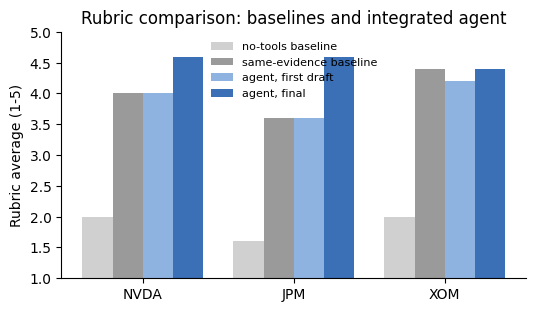

In [38]:
fig, ax = plt.subplots(figsize=(6, 3.2))
x = list(range(len(results)))
w = 0.2
series = [
    ("baseline_avg", "no-tools baseline", "#d0d0d0", -1.5 * w),
    ("matched_baseline_avg", "same-evidence baseline", "#9a9a9a", -0.5 * w),
    ("agent_first_draft", "agent, first draft", "#8fb3e0", 0.5 * w),
    ("agent_final", "agent, final", "#3b6fb6", 1.5 * w),
]
for col, label, color, offset in series:
    ax.bar([i + offset for i in x], results[col], w, label=label, color=color)
ax.set_xticks(x, results["ticker"])
ax.set_ylim(1, 5)
ax.set_ylabel("Rubric average (1-5)")
ax.set_title("Rubric comparison: baselines and integrated agent")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8)
plt.show()

In [39]:
_, tr_off, st_off = run_agent(
    TICKER, use_memory=False, reviewed_evaluation=True
)
_, tr_on, st_on = run_agent(
    TICKER, use_memory=True, reviewed_evaluation=True
)
pd.DataFrame([
    {"memory": "off", "plan_steps": len(st_off["plan"].steps),
     "notes_read": len(tr_off.select("memory", "read")[0].output),
     "final_score": st_off["evaluation"].average},
    {"memory": "on", "plan_steps": len(st_on["plan"].steps),
     "notes_read": len(tr_on.select("memory", "read")[0].output),
     "final_score": st_on["evaluation"].average},
])

,memory,plan_steps,notes_read,final_score
0,off,7,0,4.8
1,on,8,8,4.6


In [40]:
show.timing_table(trace)

,seconds
step,
evaluator,15.4
optimizer,13.9
planner,8.5
reflection,15.4
router,16.7
specialist,75.6
specialists,49.0
synthesizer,19.5


### Interpretation of C1: comparative research and memory results

**Baselines.** The no-tools baselines scored **2.0, 1.6 and 2.0** for
NVDA, JPM and XOM. The evidence-matched baselines, written from the
same findings in a single pass, scored **4.0, 3.6 and 4.4**. The agent's
kept drafts scored **4.6, 4.6 and 4.4**, all accepted at the first
revision. Most of the quality therefore comes from the evidence pipeline
(planning, retrieval and specialists), which lifts scores by about 2.5
points; the evaluate-and-revise loop and quality gate added **+0.6, +1.0
and 0.0** on top, **+0.5 on average**. A second run of the same code
measured a smaller average gap (+0.1), so the size of the loop's
contribution is not stable between runs; its direction is. These are
rubric scores from an LLM judge, not independent proof of financial
accuracy. All tool calls succeeded.

**Figures.** The verification specialist confirmed **175 of 196**
figures in the specialists' findings against raw tool data and
corrected none (NVDA 59 of 62, JPM 65 of 83, XOM 51 of 51). The 21
unmatched figures, mostly JPM's, are bank-specific measures the verifier
does not compute (for example net interest income and capital ratios),
not detected errors. The numeric audit checked **2, 4 and 0** recognized
figures in the kept briefs with **no contradictions and nothing
unverified**. The exact-string count of brief figures absent from the
findings was **12, 7 and 10** for the agent against **5, 9 and 19** for
the no-tools baseline and **11, 5 and 7** for the matched baseline; the
agent writes more figures than either baseline, and this measure counts
every rounded or re-scaled figure as unsupported.

**Memory.** With memory off, the planner wrote a **7-step** plan and the
brief scored **4.8**; with memory on, it read **8** stored lessons,
wrote an **8-step** plan that cites the lessons in four steps (B10), and
the brief scored **4.6**. Across four runs of this code the memory-on
brief never scored higher than the memory-off brief (4.4 vs 4.2, 4.6 vs
4.4, 4.6 vs 4.6, 4.8 vs 4.6). The lessons request evidence the current
tools cannot retrieve, such as a peer's valuation multiples and segment
revenue, so the plan changes but no new data reaches the writer.
Learning across runs is demonstrated at the planning level; turning it
into better briefs needs tools that can act on the lessons, which is
listed under future work.

## C2. Paired Evaluator–Optimizer acceptance analysis

This is a controlled **decision-policy ablation** using the exact same
recorded NVDA drafts and LLM rubric scores. Both acceptance rules rely on
the same GPT-6 Sol evaluator, while Claude Sonnet 5 is responsible for draft
creation and revision. The exercise compares stopping decisions; it is not
a second independent live run or an experiment with a newly trained judge.

The baseline policy requires at least one revision and average score 4.0 or
higher. The enhanced policy adds separate evidence and accuracy thresholds,
a contradiction gate for recognizable financial claims, and retention of an
acceptable earlier draft when a subsequent revision is worse. Changes in
acceptance logic alone should not be interpreted as validated gains in
financial correctness or investment performance.


In [41]:
# Compare baseline and enhanced decisions on the same scored drafts.
# This is a policy replay, not another independent model evaluation.
from src.agents import evaluator as original_eval

original_stopped = False
replay_rows = []
for index, item in enumerate(state["history"]):
    iteration = item["iteration"]
    avg = item["average"]
    if original_stopped:
        original_action = "not reached"
    else:
        original_pass = (iteration >= original_eval.MIN_ITERATIONS
                         and avg >= original_eval.PASS_THRESHOLD)
        original_budget = iteration + 1 >= original_eval.MAX_ITERATIONS
        original_action = ("accept" if original_pass else
                           "exhausted" if original_budget else "revise")
        original_stopped = original_action != "revise"

    # Action the reviewed graph ACTUALLY took at the time of this row.
    last = index == len(state["history"]) - 1
    reviewed_action = ("revise" if not last else
                       "accept" if state["accepted"] else "exhausted")
    replay_rows.append({
        "iteration": iteration,
        "rubric_average": avg,
        "accuracy": item["scores"]["accuracy"],
        "evidence": item["scores"]["evidence"],
        "original_policy": original_action,
        "reviewed_policy": reviewed_action,
        "reviewed_failures": ", ".join(item.get("failures", [])) or "none",
    })
replay = pd.DataFrame(replay_rows)
display(replay)
print("Reviewed selected iteration:", state["selected_iteration"])
print("Original policy and reviewed policy use the same rubric scores.")


,iteration,rubric_average,accuracy,evidence,original_policy,reviewed_policy,reviewed_failures
0,0,4.4,5,4,revise,revise,none
1,1,4.6,5,5,accept,accept,none


Reviewed selected iteration: 1
Original policy and reviewed policy use the same rubric scores.


### Interpretation of C2: matched evaluator policy comparison

Both policies are replayed on the **same NVDA drafts and rubric
scores**, not on two independently generated reports. In this run they
agree: both revise the first draft (4.4) because at least one revision
is required, and both accept the second (4.6). The enhanced policy's
extra gates (accuracy and evidence floors, no recognized numeric
contradictions) were all satisfied, so they did not change the outcome.
In two earlier runs, before figures were compared at written precision,
the numeric gate rejected a 4.6 draft over a rounded figure and kept a
lower-scoring revision; that behavior was a false positive and has been
corrected. The comparison shows how the acceptance rules differ in
mechanism; it does not show that either rule produces better investment
research in general.

## C3. Limitations and threats to validity

- **Data provenance and currency.** Prices, key statistics, financial
  statements, news and macro series come from external APIs (Yahoo
  Finance, NewsAPI, FRED, SEC EDGAR) or local caches and reflect the run
  date. Figures should be cross-checked against the companies' published
  filings before any investment use.
- **Judge variability.** Rubric scores come from a single LLM evaluator
  call per draft. The same code produced an agent-minus-matched-baseline
  gap of +0.1 in one run and +0.5 in the next, and the same-evidence
  baseline for JPM moved from 4.4 to 3.6 between runs. Differences of a
  few tenths between single runs are within this noise; only the gap to
  the no-tools baseline (about 2.5 points) is clearly outside it.
  Repeated evaluations and human ratings would be needed to estimate
  scoring reliability.
- **Single runs.** Each comparison in C1 rests on one run per ticker and
  condition. The results are indicative, not statistically established.
- **Numeric coverage.** The numeric audit recognizes only explicitly
  formatted claims (metric, optional fiscal year, value), so it checked
  between zero and four figures per brief. Figures are compared at the
  precision the brief writes them; an earlier exact-match version
  rejected rounded figures as contradictions, which is why two earlier
  runs kept lower-scoring drafts. A zero-contradiction audit is not a
  claim that all figures are correct.
- **Verification scope.** The verification specialist checks figures in
  the findings against the raw tool data, not against the published
  filings, and computes only common derived values (growth, margins,
  ratios, macro changes). It could not match 21 of 196 figures in this
  run, mostly bank-specific JPM measures it does not compute; those are
  unmatched, not wrong. News findings, which summarize article text, are
  not checked at all.
- **Comparison scope.** The no-tools baseline differs in available
  evidence, which the evidence-matched baseline removes; the policy
  replay shares observed scores; the memory comparison uses separate
  live runs. These answer different questions and should not be combined
  into one causal conclusion.
- **Memory.** Stored lessons changed the plan in every run but never
  raised the memory-on score, because the lessons request evidence
  (peer multiples, segment revenue) that no current tool can retrieve.
  Learning is shown at the planning level only.
- **Benchmark leakage.** The Financial PhraseBank is public and may have
  appeared in model pretraining. Classifier scores describe this
  benchmark and do not establish robustness on current market news,
  other languages or other companies.
- **Application scope.** Generated briefs are research aids, not
  verified investment recommendations. Human review of sources remains
  necessary.

## Discussion and conclusion

EquityAgent connects financial data retrieval, sentiment NLP, specialist
research, data verification, structured synthesis, iterative evaluation
and memory in one executable workflow. Part A shows that an LLM
classifier outperforms keyword and TF-IDF baselines on financial
sentiment, with errors concentrated where human annotators also
disagreed. Part B exposes every step of one research run, from plan to
stored lessons, with each figure in the findings checked against the
raw data before the brief was written. Part C separates three kinds of
evidence: rubric scores, source-grounding checks and acceptance
decisions.

Three findings stand out. First, the evidence pipeline (planning,
retrieval and specialists) accounts for most of the brief's quality:
briefs written from the agent's findings scored about 2.5 points higher
than briefs written without them. Second, the evaluate-and-revise loop
adds a smaller and less stable increment (+0.1 to +0.5 across runs);
its main value is auditability, since every acceptance decision is
recorded with its scores, critiques and numeric checks. Third, memory
changes what the agent plans but not yet how well it writes, because
the lessons it stores ask for data the tools cannot provide.

### Future work

- Tools the lessons keep requesting: peer key statistics and segment
  revenue, so that stored lessons can change the evidence, not only the
  plan.
- Repeated evaluator calls (median of three) and several runs per
  condition, to separate real effects from judge noise.
- Verification of news figures against the fetched article text, and
  bank-specific derived measures for financial-sector tickers.
- A human spot check of brief figures against the published filings.

### Reproducibility and implementation

Source code, data, tests and the notebook builder are maintained in the
[project repository](https://github.com/nicole-rowley-msaai/MS_AAI_520_NLP_GenAI_Final).
The setup cell resets the working copy to the published `main` commit,
prints that commit, and stops before any agent run if the code was
loaded from anywhere else. All model results, tables and figures are
calculated by the code cells during execution; API responses and
retrieval dates affect reproducibility. Secrets are loaded from Colab's
credential store and never written into the notebook. The automated test
suite (188 tests) runs offline with mocked models and tools; passing it
does not establish that live research claims are correct.

**AI assistance disclosure.** Generative AI tools assisted this project;
the team reviewed and tested all submitted code and is responsible for
it. ChatGPT assisted with code development, debugging, test design and
technical writing, particularly for the evaluation framework. Claude
Code (Anthropic) assisted with the NLP track (classifier diagnostics,
few-shot prompts and prompt-chain fixes), the v10 revisions (memory
ordering, numeric feedback filtering, reflection deduplication, the
evidence-matched baseline, the data verification specialist and the
rounding tolerance in the numeric audit), and the notebook's
self-checking setup. All reported results come from this notebook's
executed code cells.

### References

Brown, T. B., Mann, B., Ryder, N., Subbiah, M., Kaplan, J., Dhariwal, P.,
Neelakantan, A., Shyam, P., Sastry, G., Askell, A., Agarwal, S.,
Herbert-Voss, A., Krueger, G., Henighan, T., Child, R., Ramesh, A.,
Ziegler, D. M., Wu, J., Winter, C., … Amodei, D. (2020). Language models
are few-shot learners. *Advances in Neural Information Processing
Systems, 33*, 1877–1901. https://doi.org/10.48550/arXiv.2005.14165

Jurafsky, D., & Martin, J. H. (2026). *Speech and language processing: An
introduction to natural language processing, computational linguistics,
and speech recognition with language models* (3rd ed., draft).
https://web.stanford.edu/~jurafsky/slp3/

Lewis, P., Perez, E., Piktus, A., Petroni, F., Karpukhin, V., Goyal, N.,
Küttler, H., Lewis, M., Yih, W., Rocktäschel, T., Riedel, S., & Kiela, D.
(2020). Retrieval-augmented generation for knowledge-intensive NLP tasks.
*Advances in Neural Information Processing Systems, 33*, 9459–9474.
https://doi.org/10.48550/arXiv.2005.11401

Madaan, A., Tandon, N., Gupta, P., Hallinan, S., Gao, L., Wiegreffe, S.,
Alon, U., Dziri, N., Prabhumoye, S., Yang, Y., Gupta, S., Majumder, B. P.,
Hermann, K., Welleck, S., Yazdanbakhsh, A., & Clark, P. (2023).
Self-Refine: Iterative refinement with self-feedback. *Advances in Neural
Information Processing Systems, 36*.
https://doi.org/10.48550/arXiv.2303.17651

Malo, P., Sinha, A., Korhonen, P., Wallenius, J., & Takala, P. (2014).
Good debt or bad debt: Detecting semantic orientations in economic texts.
*Journal of the Association for Information Science and Technology,
65*(4), 782–796. https://doi.org/10.1002/asi.23062

Shinn, N., Cassano, F., Berman, E., Gopinath, A., Narasimhan, K., & Yao,
S. (2023). Reflexion: Language agents with verbal reinforcement learning.
*Advances in Neural Information Processing Systems, 36*.
https://doi.org/10.48550/arXiv.2303.11366

Wang, X., Wei, J., Schuurmans, D., Le, Q., Chi, E., Narang, S., Chowdhery,
A., & Zhou, D. (2023). Self-consistency improves chain of thought
reasoning in language models. *The Eleventh International Conference on
Learning Representations*. https://doi.org/10.48550/arXiv.2203.11171

Yao, S., Zhao, J., Yu, D., Du, N., Shafran, I., Narasimhan, K., & Cao, Y.
(2023). ReAct: Synergizing reasoning and acting in language models. *The
Eleventh International Conference on Learning Representations*. https://doi.org/10.48550/arXiv.2210.03629